# Approximation Test

In [1]:
import sys
import warnings
from itertools import combinations
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import numpy as np
from sklearn.exceptions import InconsistentVersionWarning
from sklearn.metrics import cohen_kappa_score, f1_score

In [2]:
sys.path.insert(0, "..")
from utils.constants import QUANTIZED_MIN as DOMAIN_MIN, QUANTIZED_MAX as DOMAIN_MAX

DATASET_ROOT = Path("../datasets")
MODEL_ROOT = Path("approximation")
DATASETS = {"ds1": "cicids17", "ds2": "ciciot22"}
MODELS = ("km", "lr", "nb", "slp")
VERSIONS = ("original_float", "reformulated_float", "original_fixed", "reformulated_fixed")

In [3]:
models = {}
for dataset_id, dataset in DATASETS.items():
    X_test = np.load(DATASET_ROOT / dataset / "X_test.npy")
    y_test = np.load(DATASET_ROOT / dataset / "Y_test.npy", allow_pickle=True).ravel()
    for model_type in MODELS:
        name = f"{model_type}_{dataset_id}"
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", InconsistentVersionWarning)
            model = joblib.load(MODEL_ROOT / "models" / f"{name}.joblib")
            selector = joblib.load(MODEL_ROOT / "selectors" / f"{name}_selector.joblib")
            encoder = joblib.load(MODEL_ROOT / "models" / f"{name}_label_encoder.joblib")
        models[name] = {"model": model, "model_type": model_type, "dataset": dataset,
                        "features": selector.transform(X_test).astype(np.int64),
                        "labels": encoder.transform(y_test)}

In [4]:
CELL_BUCKETS = tuple(block + lane for block in range(6) for lane in range(7)
                     if block + lane < 7)


def score_matrix(model, feature_count):
    coefficients = np.asarray(model.coef_, dtype=np.float64)
    intercepts = np.asarray(model.intercept_, dtype=np.float64).ravel()
    if len(model.classes_) == 2 and coefficients.shape[0] == 1:
        coefficients = np.vstack([np.zeros(feature_count), coefficients[0]])
        intercepts = np.array([0.0, intercepts[0]])
    return tuple(model.classes_), coefficients, intercepts


def reformulated_contributions(model, model_type):
    classes = tuple(range(model.n_clusters if model_type == "km" else len(model.classes_)))
    pairs = tuple(combinations(classes, 2))
    domain = np.arange(DOMAIN_MIN, DOMAIN_MAX + 1, dtype=np.float64)
    if model_type == "nb":
        result = np.stack([np.stack([values[left] - values[right]
                                    for values in model.feature_log_prob_])
                           for left, right in pairs])
        for i, (left, right) in enumerate(pairs):
            result[i, 0] += model.class_log_prior_[left] - model.class_log_prior_[right]
    else:
        if model_type == "km":
            coefficients = 2.0 * model.cluster_centers_
            intercepts = -np.sum(model.cluster_centers_ * model.cluster_centers_, axis=1)
        else:
            _, coefficients, intercepts = score_matrix(model, model.n_features_in_)
        result = np.stack([(coefficients[left] - coefficients[right])[:, None] * domain[None, :]
                           for left, right in pairs])
        for i, (left, right) in enumerate(pairs):
            result[i, 0] += float(intercepts[left] - intercepts[right])
    return classes, pairs, result


def pairwise_predictions(scores, classes, pairs):
    votes = np.zeros((len(scores), len(classes)), dtype=np.int64)
    for i, (left, right) in enumerate(pairs):
        votes[:, left] += scores[:, i] >= 0
        votes[:, right] += scores[:, i] < 0
    return votes.argmax(axis=1)



def original_contributions(model, model_type):
    domain = np.arange(DOMAIN_MIN, DOMAIN_MAX + 1, dtype=np.float64)
    if model_type == "km":
        return -(domain[None, None, :] - model.cluster_centers_[:, :, None]) ** 2
    if model_type == "nb":
        contributions = np.stack(
            [values[:, domain.astype(np.int64)] for values in model.feature_log_prob_], axis=1
        )
        contributions[:, 0, :] += model.class_log_prior_[:, None]
        return contributions
    _, coefficients, intercepts = score_matrix(model, model.n_features_in_)
    contributions = coefficients[:, :, None] * domain[None, None, :]
    contributions[:, 0, :] += intercepts[:, None]
    return contributions


def accumulate(contributions, features):
    scores = np.zeros((len(features), contributions.shape[0]), dtype=contributions.dtype)
    for feature_slot in range(features.shape[1]):
        scores += contributions[:, feature_slot, features[:, feature_slot] - DOMAIN_MIN].T
    return scores


def scale_fits(contributions, scale):
    rounded = np.rint(contributions * scale)
    low, high = rounded.min(axis=2), rounded.max(axis=2)
    if np.any(low < -32768) or np.any(high > 32767):
        return False
    buckets = np.asarray(CELL_BUCKETS[:contributions.shape[1]])
    ranges = np.array([(low[:, buckets == bucket].sum(axis=1),
                        high[:, buckets == bucket].sum(axis=1))
                       for bucket in range(7)])
    prefixes = ranges.cumsum(axis=0)
    return bool(np.all(ranges[:, 0] >= -32768) and np.all(ranges[:, 1] <= 32767)
                and np.all(prefixes[:, 0] >= -32768) and np.all(prefixes[:, 1] <= 32767))


def quantize(contributions):
    contributions = np.asarray(contributions, dtype=np.float64)
    factor = 1.0
    normalized = contributions
    while not scale_fits(normalized, 1):
        factor *= 2.0
        if not np.isfinite(factor):
            raise ValueError("Score normalization factor overflowed")
        normalized = contributions / factor
    low, high, best = 1, 32767, 1
    while low <= high:
        scale = (low + high) // 2
        if scale_fits(normalized, scale):
            best, low = scale, scale + 1
        else:
            high = scale - 1
    return np.rint(normalized * best).astype(np.int64)

In [5]:
def evaluate_model(name, artifacts):
    model, model_type = artifacts["model"], artifacts["model_type"]
    features, labels = artifacts["features"], artifacts["labels"]
    classes, pairs, reformulated = reformulated_contributions(model, model_type)
    original = model.predict(features)
    contributions = original_contributions(model, model_type)
    predictions = (
        original,
        pairwise_predictions(accumulate(reformulated, features), classes, pairs),
        accumulate(quantize(contributions), features).argmax(axis=1),
        pairwise_predictions(accumulate(quantize(reformulated), features), classes, pairs),
    )
    return [{"model": name, "dataset": artifacts["dataset"], "variant": variant,
             "macro_f1": f1_score(labels, prediction, labels=list(classes), average="macro", zero_division=0),
             "kappa_vs_original": cohen_kappa_score(original, prediction)}
            for variant, prediction in zip(VERSIONS, predictions)]


results = [row for name, artifacts in models.items() for row in evaluate_model(name, artifacts)]

# Plot Figure 12(a) and Figure 12(b)

In [6]:
FIGURE_SIZE = (10, 4)
HATCHES = ("///", "\\\\", "xxx", "...")
COLORS = tuple(tuple(0.6 * channel + 0.4 for channel in to_rgb(color))
               for color in ("tab:blue", "tab:orange", "tab:green", "tab:red"))


def plot_approx_error(dataset):
    rows = [row for row in results if row["dataset"] == dataset]
    values = {(row["model"].split("_")[0], row["variant"]): row for row in rows}
    plt.rcParams.update({"font.family": "Times New Roman", "font.size": 14, "pdf.fonttype": 42})
    figure, f1_axis = plt.subplots(figsize=FIGURE_SIZE)
    kappa_axis = f1_axis.twinx()
    width = 0.18
    for model_index, model in enumerate(MODELS):
        positions = model_index + (np.arange(4) - 1.5) * width
        f1 = [values[(model, version)]["macro_f1"] for version in VERSIONS]
        kappa = [values[(model, version)]["kappa_vs_original"] for version in VERSIONS]
        for index, position in enumerate(positions):
            f1_axis.bar(position, f1[index], width=width, facecolor=COLORS[index],
                        edgecolor="black", linewidth=0.8, hatch=HATCHES[index])
        kappa_axis.plot(positions, kappa, color="black", marker="o", markersize=5,
                        linewidth=1.5, clip_on=False)
        for index, (position, value) in enumerate(zip(positions, kappa)):
            text = "1.0" if value == 1 else f"{min(np.trunc(value * 1000) / 1000, 0.99):.2f}"
            above = index % 2 == 0
            kappa_axis.annotate(text, (position, value), xytext=(0, 5 if above else -5),
                                textcoords="offset points", ha="center", va="bottom" if above else "top",
                                color="black", fontsize=20, annotation_clip=False, clip_on=False)
    for axis, label in ((f1_axis, "Macro-F1"), (kappa_axis, "Cohen’s kappa")):
        axis.set_xticks(np.arange(len(MODELS)), [model.upper() for model in MODELS])
        axis.set_ylabel(label, fontsize=24)
        axis.tick_params(axis="both", which="both", labelsize=24)
        axis.set_axisbelow(True)
        axis.spines["top"].set_visible(False)
    f1_axis.set_ylim(0, max(bar.get_height() for bar in f1_axis.patches) + 0.20)
    kappa_axis.set_ylim(0, 1)
    f1_axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

## Plot Figure 12(a)

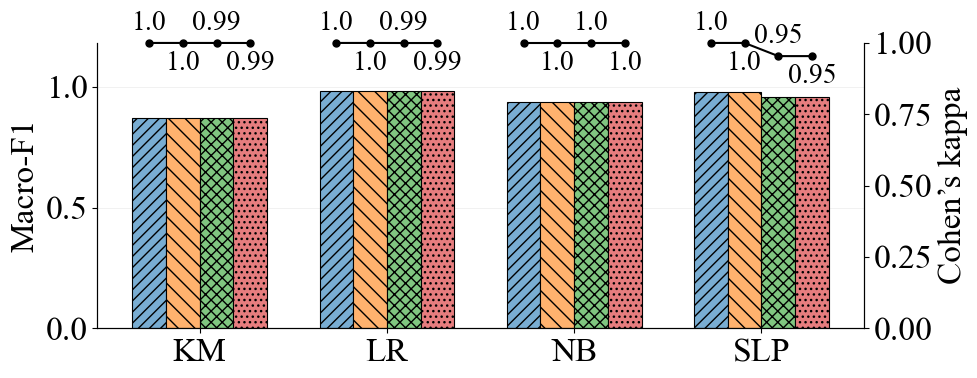

In [7]:
plot_approx_error("cicids17")

## Plot Figure 12(b)

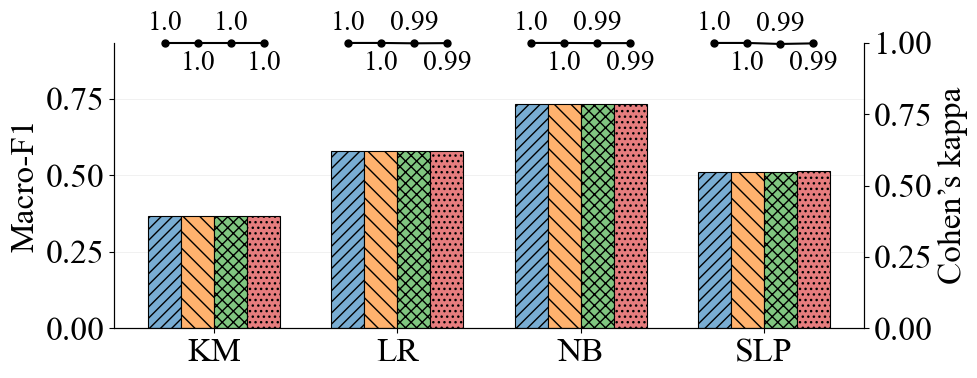

In [8]:
plot_approx_error("ciciot22")